# Chest X-Ray Pneumonia — Feature Engineering and Scaling

We turn images into numerical features, inspect them, demonstrate feature scaling without leakage and save prepared data for notebook 03. This follows the small-step style of the [feature engineering reference](https://github.com/tejuuu-7774/Inventory-demand-forecasting/blob/main/Notebooks/02_feature_engineering.ipynb). Run notebook 01 first. All three Colab notebooks use the same Google Drive project folder. Pixel normalization is fixed; standardization learns training statistics.

## 1. Import libraries

Pillow preprocesses images; NumPy computes explicit descriptors; scikit-learn handles grouping and scaling.

In [1]:
import sys, json, hashlib, re, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Image as NotebookImage
SEED = 42
CLASSES = {'NORMAL': 0, 'PNEUMONIA': 1}
IN_COLAB = importlib.util.find_spec('google.colab') is not None
print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
import joblib

def show_plot(name):
    path = FIGURE_DIR / name
    plt.gcf().text(.01, .005, 'Source: local Kaggle chest_xray download; supplied splits; exploratory summaries', fontsize=8)
    plt.tight_layout(rect=(0,.025,1,1))
    plt.savefig(path, dpi=140)
    plt.close()
    display(NotebookImage(filename=str(path)))

Environment: Local Python


## 2. Find the project folders

Use the same project folder as notebook 01 so this stage loads its audited manifest.

In [2]:
# Use the SAME PROJECT_ROOT in all three notebooks.
# Colab: put the extracted images under MyDrive/chest_xray before running.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Chest-Xray-Pneumonia-ML')
    DATA_ROOT = Path('/content/drive/MyDrive/chest_xray')
else:
    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == 'Notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_ROOT = Path.home() / 'Downloads/chest_xray'
OUTPUT = PROJECT_ROOT
for folder in ('Datasets/processed','results','report/figures','models'):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = PROJECT_ROOT / 'Datasets/processed'
FIGURE_DIR = PROJECT_ROOT / 'report/figures'
print('Project folder:', PROJECT_ROOT)
print('Raw data folder:', DATA_ROOT)

Project folder: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML
Raw data folder: /Users/ravichandrashinde/Downloads/chest_xray


## 3. Load the audited image records

Check that the EDA stage completed. Do not silently recompute or change its exclusions.

In [3]:
manifest_path=PROCESSED_DIR/'manifest.csv'
if not manifest_path.exists(): raise FileNotFoundError('Run notebook 01 first, using the same PROJECT_ROOT.')
images=pd.read_csv(manifest_path,keep_default_na=False)
audit_summary=json.loads((OUTPUT/'results/dataset_audit.json').read_text())
root=DATA_ROOT
if not (root/'train').exists(): root=root/'chest_xray'
print('Audited records:',images.shape)
display(pd.crosstab(images.partition,images.label))

Audited records: (5856, 16)


label,NORMAL,PNEUMONIA
partition,,
development,1348,3405
excluded,4,481
test,231,387


## 4. Set the experiment settings

Keep seed, labels, image size, folds and feature definitions fixed before model evaluation.

In [4]:
IMAGE_SIZE=(64,64)
N_FOLDS=3
config={'seed':SEED,'image_size':IMAGE_SIZE,'n_folds':N_FOLDS,'positive_class':'PNEUMONIA','selection_metric':'balanced_accuracy','feature_version':1}
print(json.dumps(config,indent=2))

{
  "seed": 42,
  "image_size": [
    64,
    64
  ],
  "n_folds": 3,
  "positive_class": "PNEUMONIA",
  "selection_metric": "balanced_accuracy",
  "feature_version": 1
}


## 5. Resize and normalize an example image

Preserve aspect ratio and pad to 64×64. Divide pixels by 255; this operation learns no dataset statistics.

Normalized pixel range: 0.0 0.94509804


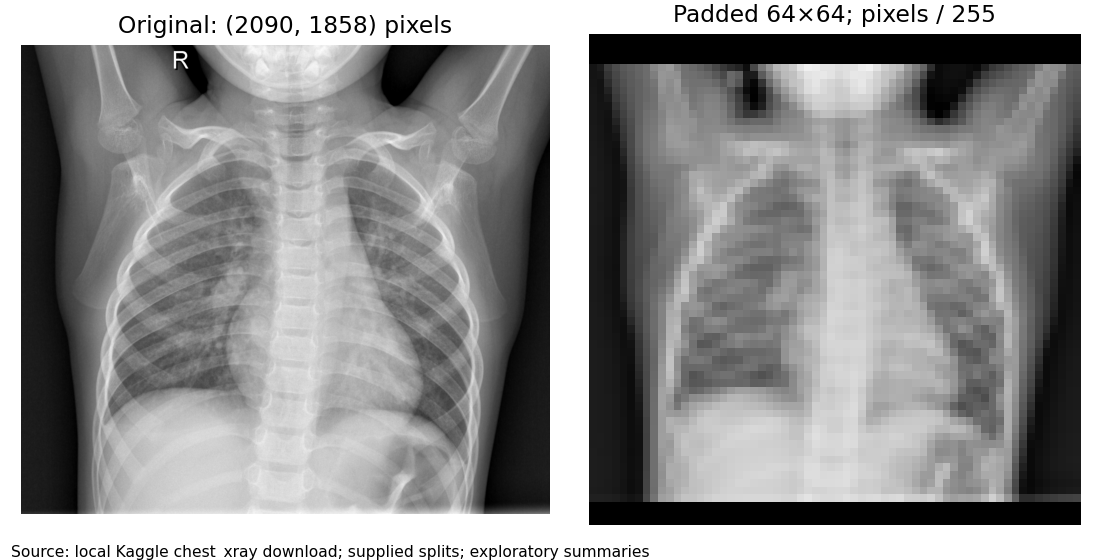

In [5]:
example=images[images.partition=='development'].iloc[0]
with Image.open(root/example.path) as im:
    original=im.convert('L')
    resized=ImageOps.pad(original,IMAGE_SIZE,method=Image.Resampling.BILINEAR,color=0)
    normalized=np.asarray(resized,dtype=np.float32)/255
    fig,axes=plt.subplots(1,2,figsize=(8,4))
    axes[0].imshow(original,cmap='gray'); axes[0].set_title(f'Original: {original.size} pixels')
    axes[1].imshow(normalized,cmap='gray',vmin=0,vmax=1); axes[1].set_title('Padded 64×64; pixels / 255')
    for ax in axes: ax.axis('off')
show_plot('feature_preprocessing.png')
print('Normalized pixel range:', normalized.min(), normalized.max())

## 6. Define the image descriptors

HOG encodes local gradients; uniform square-neighbor LBP encodes texture; histograms and summaries encode intensity. The code explicitly states sampling and normalization. Padding/artifacts can remain confounders. No filename/metadata predictors are used.

In [6]:
def save_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))


def texture_features(x, u8):
    """Explicit NumPy descriptors: unsigned HOG and square-neighborhood LBP.

    HOG: 9 orientation bins, linear orientation votes, 8x8 cells,
    2x2 overlapping blocks, L2-Hys. No spatial interpolation of cell votes.
    LBP: 8 immediate neighbors (diagonals at sqrt(2)), uniform rotation-
    invariant code = number of ones if <=2 transitions, otherwise bin 9.
    This square-neighborhood LBP is not circular interpolated radius-1 LBP.
    """
    gy, gx = np.gradient(x)
    mag = np.hypot(gx, gy)
    angle = (np.degrees(np.arctan2(gy,gx)) % 180) / 20
    lower = np.floor(angle).astype(int) % 9
    fraction = angle - np.floor(angle)
    rr, cc = np.indices(x.shape)
    cells = np.zeros((8,8,9),dtype=np.float32)
    np.add.at(cells,(rr//8,cc//8,lower),mag*(1-fraction))
    np.add.at(cells,(rr//8,cc//8,(lower+1)%9),mag*fraction)
    blocks=[]
    for r in range(7):
        for c in range(7):
            block=cells[r:r+2,c:c+2].ravel().copy()
            block/=np.sqrt(np.dot(block,block)+1e-10)
            block=np.minimum(block,.2)
            block/=np.sqrt(np.dot(block,block)+1e-10)
            blocks.append(block)
    center=u8[1:-1,1:-1]
    offsets=[(-1,-1),(-1,0),(-1,1),(0,1),(1,1),(1,0),(1,-1),(0,-1)]
    bits=np.stack([u8[1+dr:63+dr,1+dc:63+dc]>=center for dr,dc in offsets])
    transitions=np.sum(bits!=np.roll(bits,1,axis=0),axis=0)
    codes=np.where(transitions<=2,bits.sum(axis=0),9)
    lh=np.bincount(codes.ravel(),minlength=10).astype(float)
    return np.concatenate(blocks),lh/lh.sum()


def extract_one(path):
    with Image.open(path) as im:
        # Preserve anatomy proportions; padding is fixed, not learned.
        image = ImageOps.pad(im.convert('L'), (64,64), method=Image.Resampling.BILINEAR, color=0)
        u8 = np.asarray(image)
    x = u8.astype(np.float32) / 255.0
    h, lh = texture_features(x,u8)
    ih = np.histogram(x, bins=16, range=(0,1))[0].astype(float) / x.size
    stats = np.array([x.mean(), x.std(), *np.quantile(x,[.1,.25,.5,.75,.9]),
                      np.mean(np.abs(np.diff(x,axis=0))), np.mean(np.abs(np.diff(x,axis=1)))])
    return np.concatenate([h, lh, ih, stats]).astype(np.float32)


def features(root, df, out):
    selected = df[df.partition != 'excluded'].copy().reset_index(drop=True)
    x = np.stack([extract_one(root / path) for path in selected.path])
    assert np.isfinite(x).all()
    np.savez_compressed(out / 'Datasets/processed/features.npz', X=x, y=selected.target.to_numpy())
    selected.to_csv(out / 'Datasets/processed/retained_manifest.csv', index=False)
    save_json({'size':[64,64], 'features':x.shape[1], 'hog':1764, 'lbp':10, 'intensity_histogram':16,
               'summary_statistics':9,'pixel_normalization':'divide by 255 (fixed)',
               'learned_scaling':'StandardScaler fitted within CV pipeline; never on test'}, out / 'results/features.json')
    return selected, x

## 7. Extract features for the retained images

All features are computed per image. No dataset-fitted transform is applied at this stage. The 1,799 columns consist of 1,764 HOG, ten LBP, sixteen histogram and nine summary values.

In [7]:
retained,X=features(root,images,OUTPUT)
y=retained.target.to_numpy()
print('Features:',X.shape,'Labels:',y.shape)
print('All values finite:',np.isfinite(X).all())
display(pd.DataFrame(X[:5,-9:],columns=['mean','std','p10','p25','p50','p75','p90','vertical_difference','horizontal_difference']))

Features: (5371, 1799) Labels: (5371,)
All values finite: True


,mean,std,p10,p25,p50,p75,p90,vertical_difference,horizontal_difference
0,0.450115,0.275353,0.0,0.176471,0.501961,0.678431,0.796078,0.042707,0.042054
1,0.320725,0.256430,0.0,0.011765,0.315686,0.541176,0.676471,0.046197,0.038792
2,0.381160,0.305215,0.0,0.000000,0.411765,0.666667,0.776471,0.041272,0.036147
3,0.415579,0.306833,0.0,0.043137,0.486275,0.694118,0.788235,0.039373,0.033392
4,0.292904,0.281278,0.0,0.000000,0.282353,0.552941,0.698039,0.044135,0.036162


## 8. Separate development and test

This split is inherited from the audit. Test labels never select preprocessing, model settings or thresholds.

In [8]:
dev=retained.partition.eq('development').to_numpy()
X_dev,y_dev=X[dev],y[dev]
groups=retained.group.to_numpy()[dev]
assert not set(groups)&set(retained.loc[~dev,'group'])
print('Development:',X_dev.shape,'Test:',X[~dev].shape)

Development: (4753, 1799) Test: (618, 1799)


## 9. Create grouped cross-validation folds

StratifiedGroupKFold approximately balances labels while keeping each filename/hash component within one fold. These are patient proxies, not certified identities.

In [9]:
cv=list(StratifiedGroupKFold(N_FOLDS,shuffle=True,random_state=SEED).split(X_dev,y_dev,groups))
fold_rows=[]
for fold,(tr,va) in enumerate(cv):
    assert not set(groups[tr])&set(groups[va])
    fold_rows.append({'fold':fold,'training_images':len(tr),'validation_images':len(va),'validation_pneumonia_percent':100*y_dev[va].mean()})
display(pd.DataFrame(fold_rows))

,fold,training_images,validation_images,validation_pneumonia_percent
0,0,3168,1585,71.608833
1,1,3169,1584,71.654040
2,2,3169,1584,71.654040


## 10. Fit a scaler on one training fold

For each feature, $z=(x-\mu_{train})/\sigma_{train}$. Fit only on fold 0 training rows. The model notebook refits a separate scaler inside every CV fit.

In [10]:
train_idx,val_idx=cv[0]
scaler=StandardScaler().fit(X_dev[train_idx])
X_train_scaled=scaler.transform(X_dev[train_idx])
X_val_scaled=scaler.transform(X_dev[val_idx])
print('Scaler training rows:',scaler.n_samples_seen_)
print('Largest absolute scaled training mean:',np.abs(X_train_scaled.mean(axis=0)).max())
print('Validation means need not be zero:',np.abs(X_val_scaled.mean(axis=0)).mean())

Scaler training rows: 3168.0
Largest absolute scaled training mean: 6.6593984e-06
Validation means need not be zero: 0.033626813


## 11. Compare features before and after scaling

Inspect statistics from the training fold only. StandardScaler changes feature scales; it does not make features normally distributed.

,feature_index,before_mean,before_std,after_mean,after_std
0,1764,0.01624,0.00451,-0.0,1.0
1,1774,0.33367,0.11514,-0.0,1.0
2,1790,0.34932,0.08146,0.0,1.0
3,1798,0.02928,0.00892,0.0,1.0


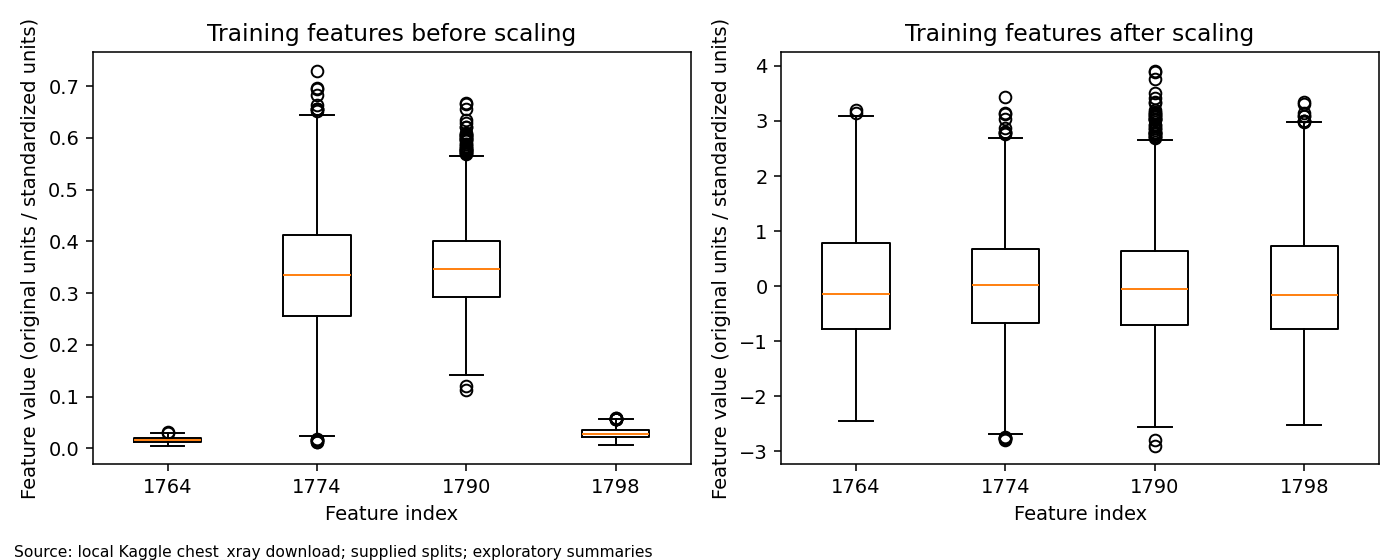

In [11]:
columns=[1764,1774,1790,1798]
comparison=pd.DataFrame({'feature_index':columns,'before_mean':X_dev[train_idx][:,columns].mean(0),'before_std':X_dev[train_idx][:,columns].std(0),'after_mean':X_train_scaled[:,columns].mean(0),'after_std':X_train_scaled[:,columns].std(0)})
display(comparison.round(5))
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].boxplot(X_dev[train_idx][:,columns],tick_labels=[str(c) for c in columns]); axes[0].set_title('Training features before scaling')
axes[1].boxplot(X_train_scaled[:,columns],tick_labels=[str(c) for c in columns]); axes[1].set_title('Training features after scaling')
for ax in axes: ax.set(xlabel='Feature index',ylabel='Feature value (original units / standardized units)')
show_plot('feature_scaling_comparison.png')

## 12. Save prepared data and settings

Notebook 03 receives raw per-image features so its Pipeline learns scaling independently within every training fold. The scaled fold arrays below are demonstration artifacts only.

In [12]:
np.savez_compressed(PROCESSED_DIR/'fold0_scaling_demo.npz',X_train_scaled=X_train_scaled,X_validation_scaled=X_val_scaled,train_idx=train_idx,val_idx=val_idx)
joblib.dump(scaler,OUTPUT/'models/fold0_scaler_demo.joblib')
(PROCESSED_DIR/'phase1_config.json').write_text(json.dumps(config,indent=2))
print('Saved features.npz, retained_manifest.csv, phase1_config.json and fold-0 scaling demonstration.')

Saved features.npz, retained_manifest.csv, phase1_config.json and fold-0 scaling demonstration.


## 13. Feature engineering conclusions

We preserved aspect ratio, normalized pixels, computed 1,799 reproducible image features, verified group isolation and demonstrated training-only standardization. Random forests do not need scaling. Logistic regression and SVM use scaling inside their CV pipelines. Never train every model on the globally pre-scaled fold demonstration arrays.

References: [HOG](https://doi.org/10.1109/CVPR.2005.177), [LBP](https://doi.org/10.1109/TPAMI.2002.1017623), [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html). Our exact NumPy variants are documented in the descriptor function. Proceed to notebook 03.